In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')
path = kagglehub.dataset_download("habibaishfaq/diabetes-prediction")
print("Path to dataset files:", path)

/kaggle/input/datasets/habibaishfaq/diabetes-prediction/diabetes_prediction_dataset.csv
Path to dataset files: /kaggle/input/datasets/habibaishfaq/diabetes-prediction


In [2]:
df = pd.read_csv("/kaggle/input/datasets/habibaishfaq/diabetes-prediction/diabetes_prediction_dataset.csv")
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [3]:
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB
None
                 age  hypertension  heart_disease            bmi  \
count  100000.000000  100000.00000  100000.000000  100000.000000   
mean       41.885856       0.07485       0.039420      27.320767   
std        22.516840       0.26315       0.194593       6.6

In [4]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [5]:
old_len = len(df)

df = df.drop_duplicates().copy()

new_len = len(df)

print("Removed:", old_len - new_len, "duplicate rows")
print("Updated Shape:", df.shape)

Removed: 3854 duplicate rows
Updated Shape: (96146, 9)


In [6]:
print(df['diabetes'].value_counts())

print("\nPercentage Distribution:")
print(df['diabetes'].value_counts(normalize=True) * 100)

diabetes
0    87664
1     8482
Name: count, dtype: int64

Percentage Distribution:
diabetes
0    91.178
1     8.822
Name: proportion, dtype: float64


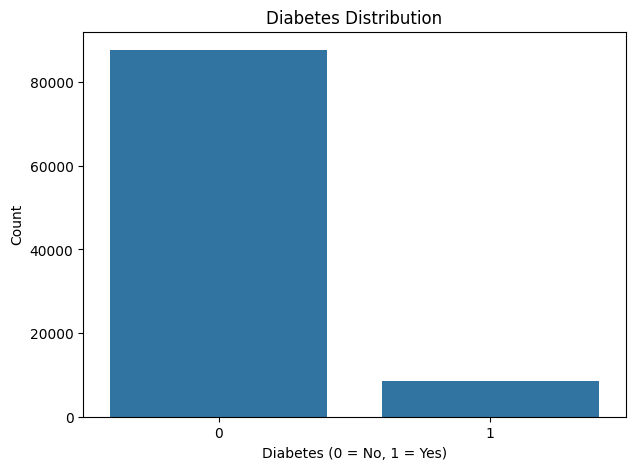

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='diabetes')

plt.title("Diabetes Distribution")
plt.xlabel("Diabetes (0 = No, 1 = Yes)")
plt.ylabel("Count")

plt.show()

In [8]:
categorical_cols = ['gender', 'smoking_history']

for col in categorical_cols:
    print(f"\n{col} Distribution:")
    print(df[col].value_counts())


gender Distribution:
gender
Female    56161
Male      39967
Other        18
Name: count, dtype: int64

smoking_history Distribution:
smoking_history
never          34398
No Info        32887
former          9299
current         9197
not current     6367
ever            3998
Name: count, dtype: int64


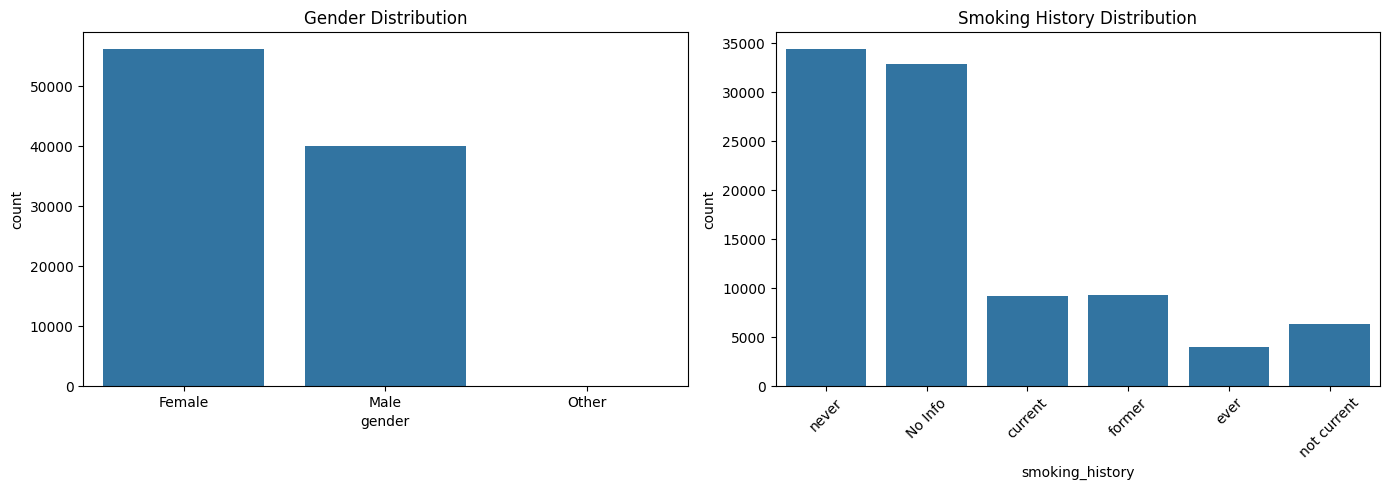

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x='gender', ax=axes[0])
axes[0].set_title("Gender Distribution")

sns.countplot(data=df, x='smoking_history', ax=axes[1])
axes[1].set_title("Smoking History Distribution")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

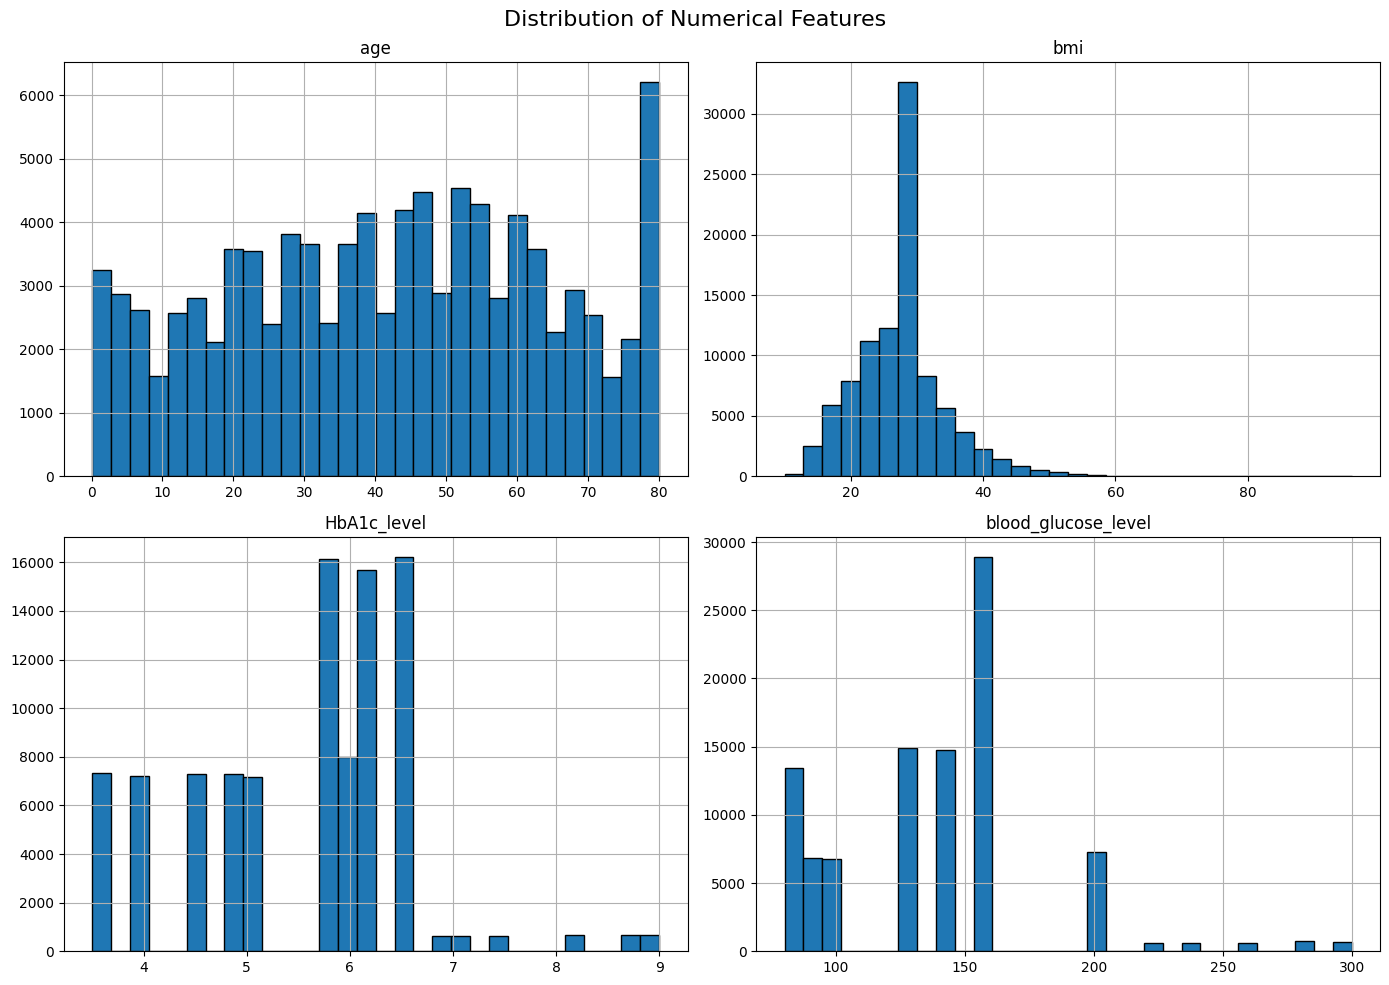

In [10]:
numerical_cols = [
    'age',
    'bmi',
    'HbA1c_level',
    'blood_glucose_level'
]

df[numerical_cols].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor='black'
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

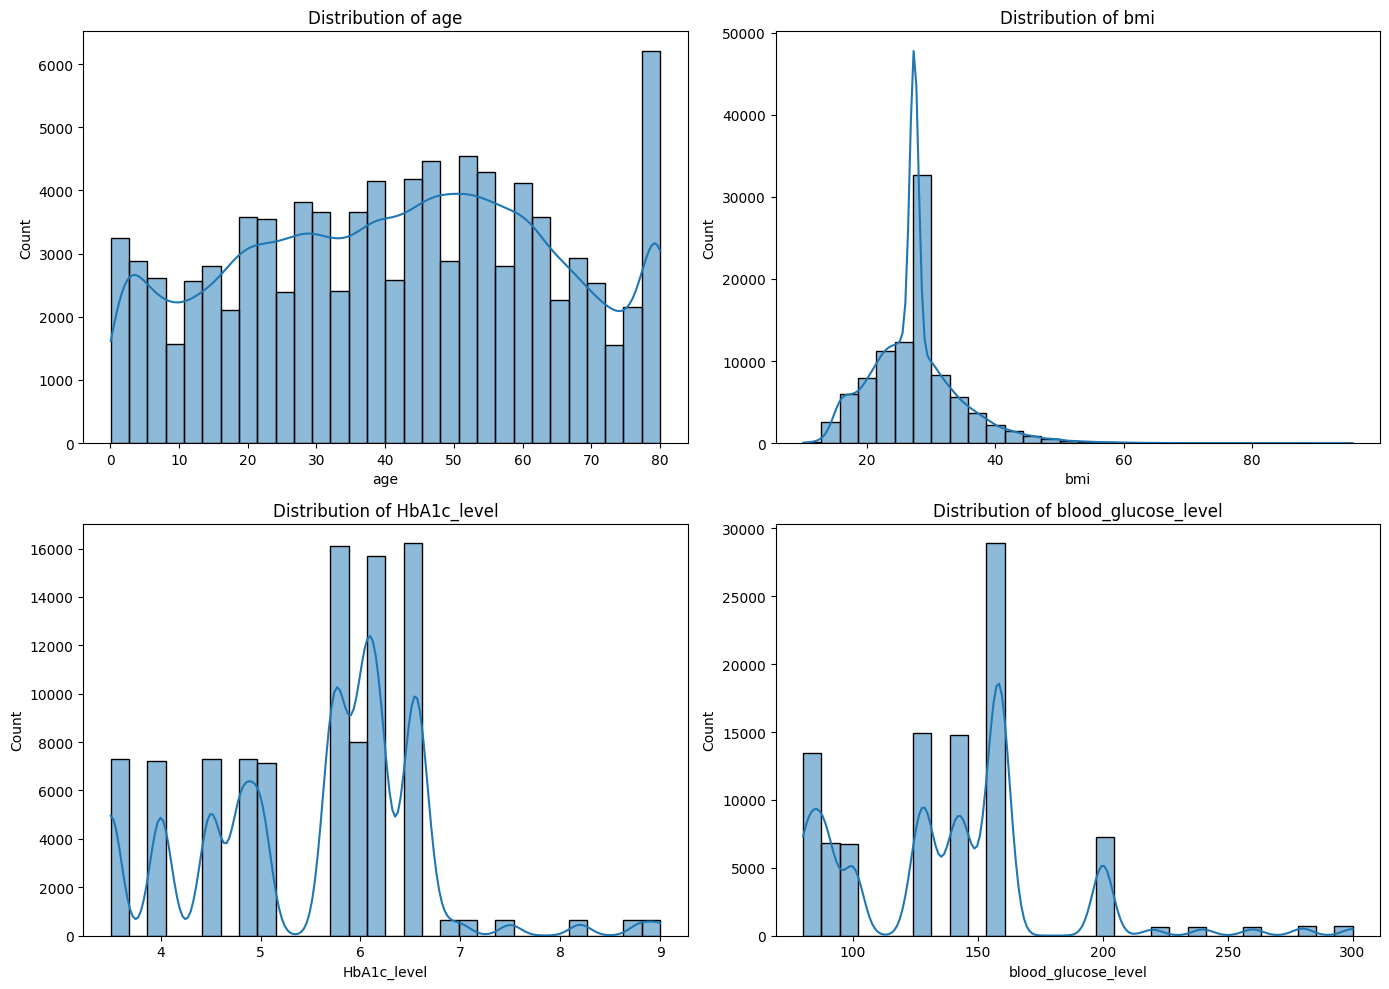

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for col, ax in zip(numerical_cols, axes.flatten()):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30,
        ax=ax
    )
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

In [12]:
print(df[numerical_cols].describe().T)

                       count        mean        std    min    25%     50%  \
age                  96146.0   41.794326  22.462948   0.08   24.0   43.00   
bmi                  96146.0   27.321461   6.767716  10.01   23.4   27.32   
HbA1c_level          96146.0    5.532609   1.073232   3.50    4.8    5.80   
blood_glucose_level  96146.0  138.218231  40.909771  80.00  100.0  140.00   

                        75%     max  
age                   59.00   80.00  
bmi                   29.86   95.69  
HbA1c_level            6.20    9.00  
blood_glucose_level  159.00  300.00  


In [13]:
skewness = df[numerical_cols].skew()

print("Skewness of Numerical Features:")
print(skewness.sort_values(ascending=False))

Skewness of Numerical Features:
bmi                    1.023751
blood_glucose_level    0.836489
HbA1c_level           -0.054463
age                   -0.062445
dtype: float64


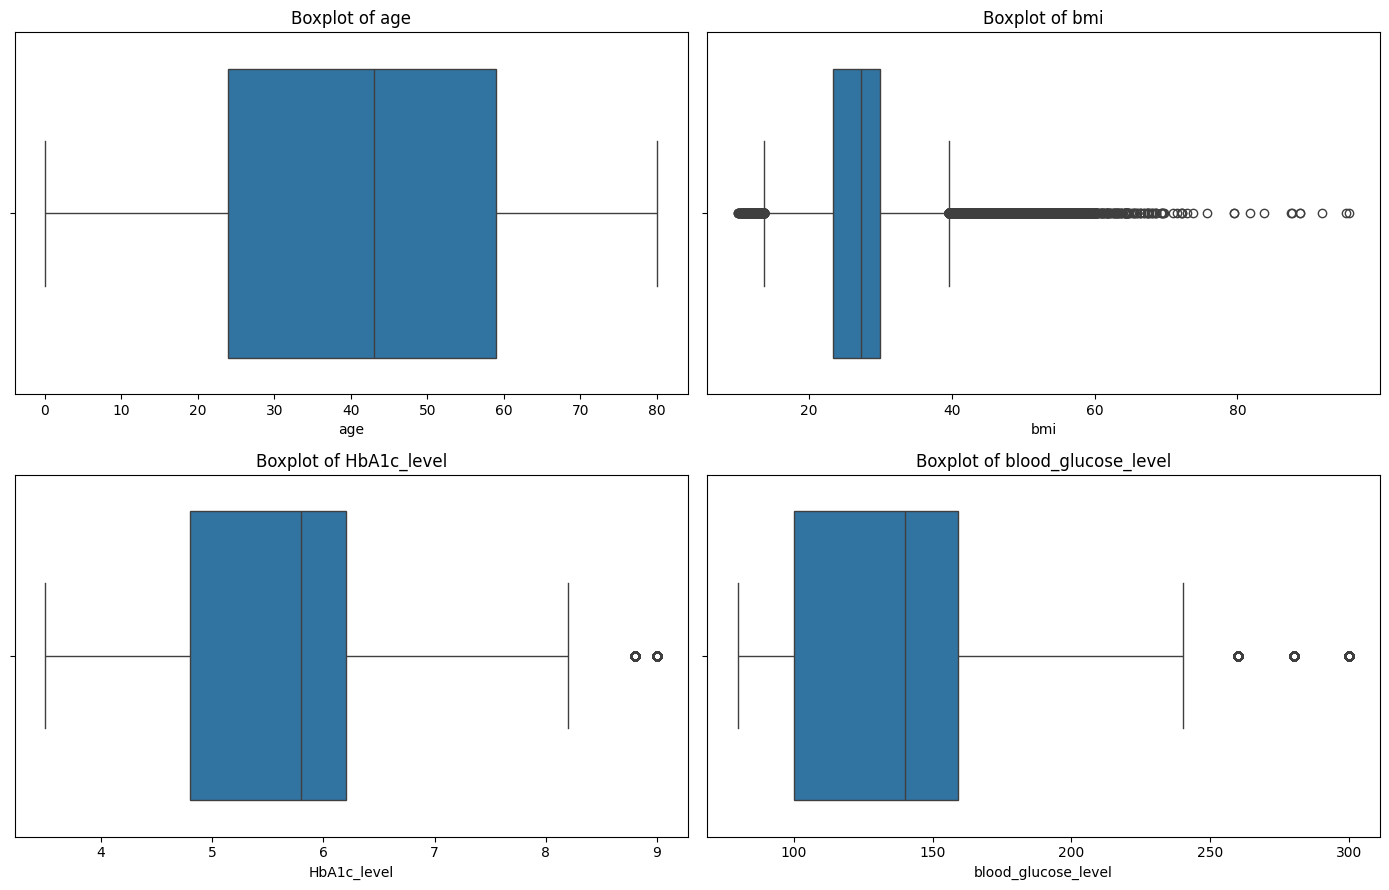

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for col, ax in zip(numerical_cols, axes.flatten()):
    sns.boxplot(data=df, x=col, ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

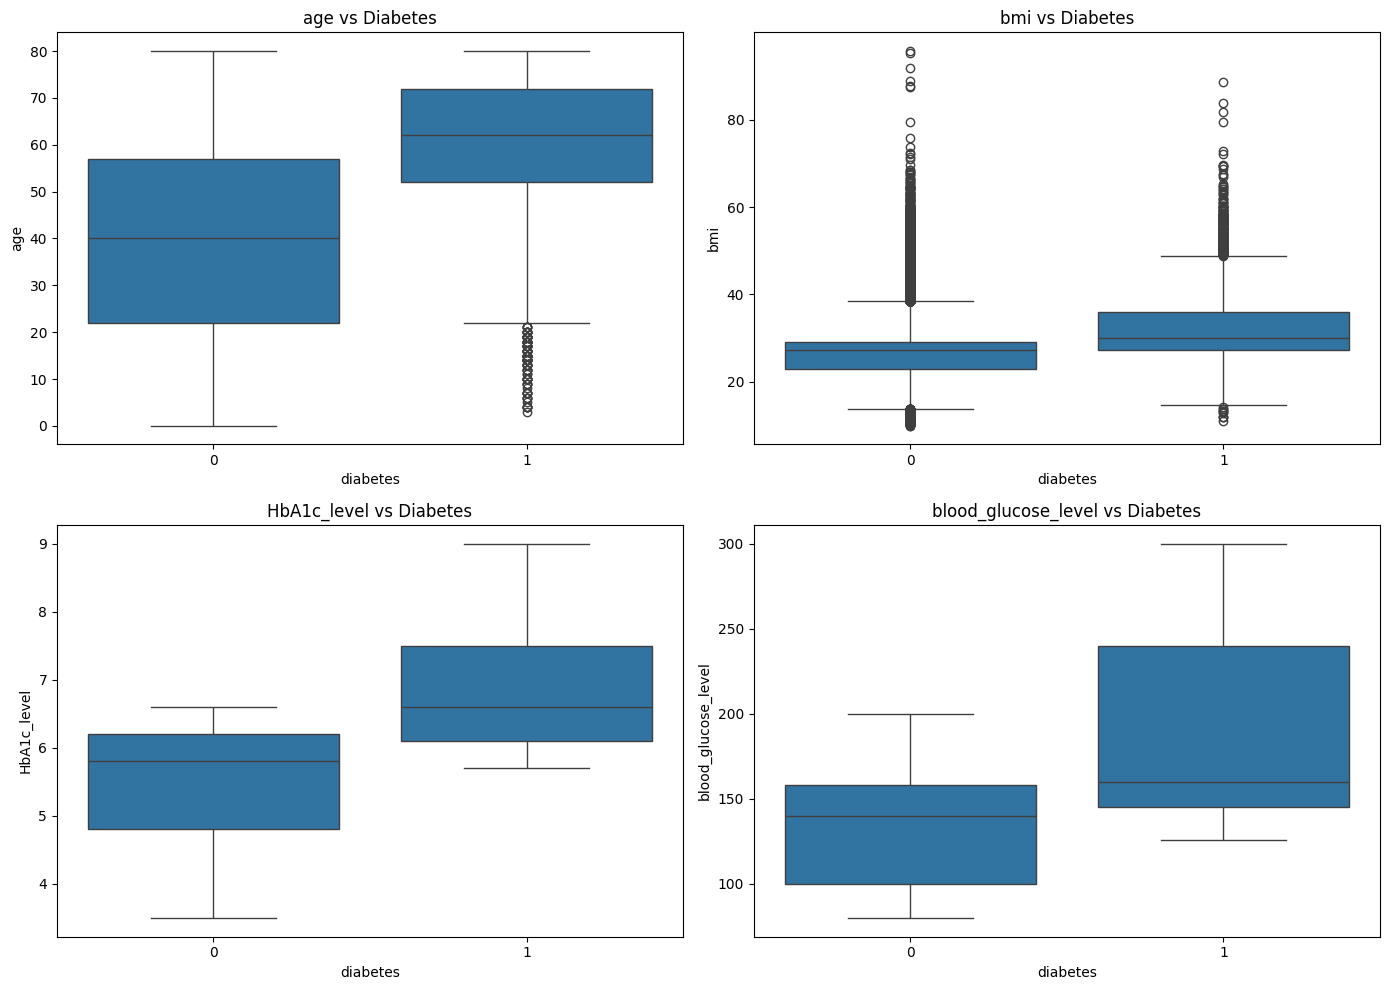

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for col, ax in zip(numerical_cols, axes.flatten()):
    sns.boxplot(
        data=df,
        x='diabetes',
        y=col,
        ax=ax
    )
    ax.set_title(f'{col} vs Diabetes')

plt.tight_layout()
plt.show()

In [16]:
categorical_cols = ['gender', 'smoking_history']

for col in categorical_cols:

    print(f"\nDiabetes Rate by {col}:")

    result = df.groupby(col)['diabetes'].agg(
        ['count', 'sum', 'mean']
    )

    result['diabetes_percentage'] = result['mean'] * 100

    print(result.round(2))


Diabetes Rate by gender:
        count   sum  mean  diabetes_percentage
gender                                        
Female  56161  4447  0.08                 7.92
Male    39967  4035  0.10                10.10
Other      18     0  0.00                 0.00

Diabetes Rate by smoking_history:
                 count   sum  mean  diabetes_percentage
smoking_history                                        
No Info          32887  1445  0.04                 4.39
current           9197   948  0.10                10.31
ever              3998   472  0.12                11.81
former            9299  1590  0.17                17.10
never            34398  3337  0.10                 9.70
not current       6367   690  0.11                10.84


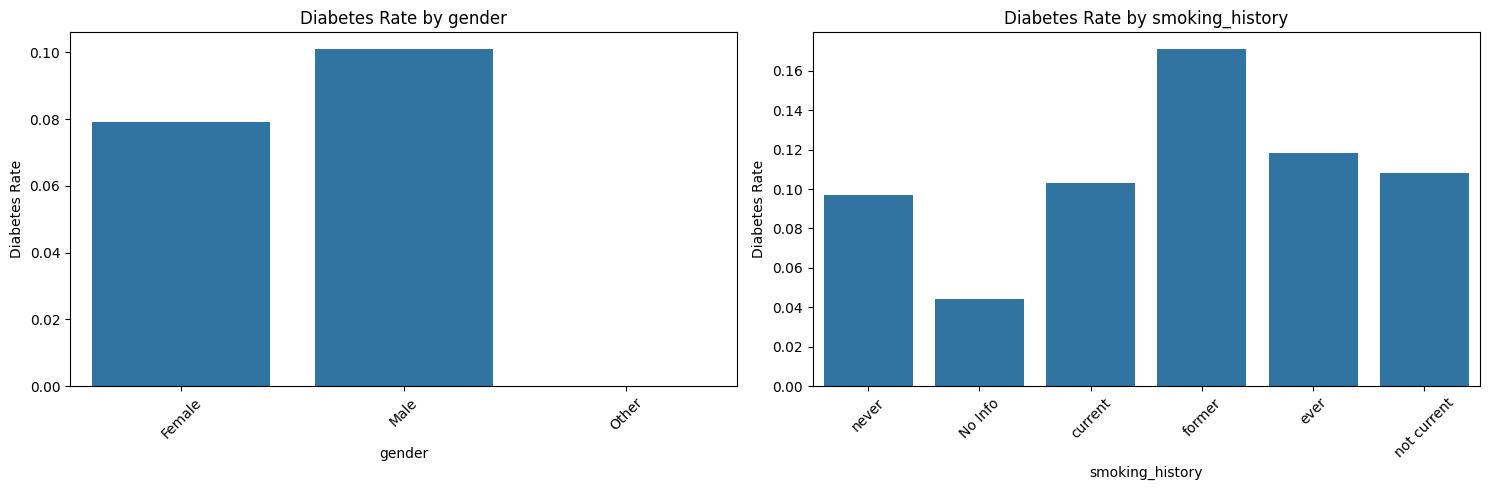

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for col, ax in zip(categorical_cols, axes):

    sns.barplot(
        data=df,
        x=col,
        y='diabetes',
        errorbar=None,
        ax=ax
    )

    ax.set_title(f'Diabetes Rate by {col}')
    ax.set_ylabel('Diabetes Rate')
    ax.set_xlabel(col)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

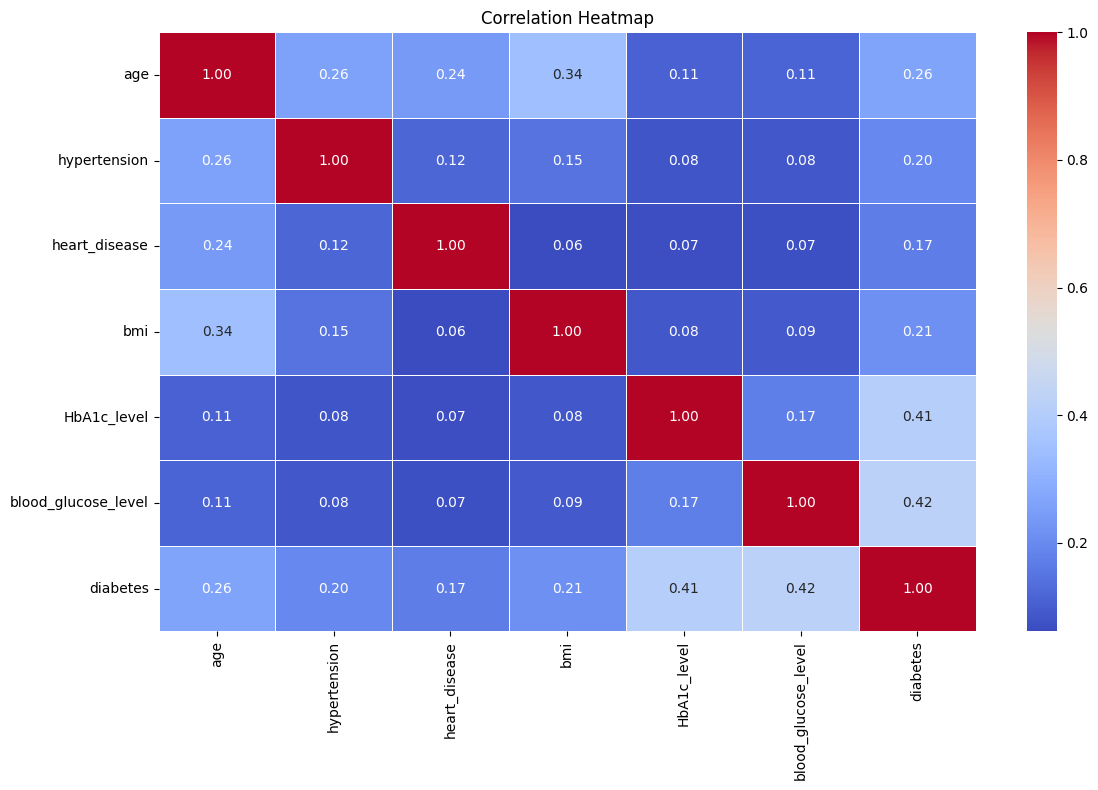

In [18]:
plt.figure(figsize=(12, 8))

corr = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [19]:
target_corr = corr['diabetes'].drop('diabetes')

target_corr = target_corr.sort_values(
    ascending=False
)

print("Correlation with Diabetes:")
print(target_corr)

Correlation with Diabetes:
blood_glucose_level    0.424336
HbA1c_level            0.406408
age                    0.264927
bmi                    0.214932
hypertension           0.195710
heart_disease          0.170711
Name: diabetes, dtype: float64


Done with EDA and understanding of the data

In [20]:
X = df.drop(columns=['diabetes'])
y = df['diabetes']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts(normalize=True) * 100)

Feature Shape: (96146, 8)
Target Shape: (96146,)

Target Distribution:
diabetes
0    91.178
1     8.822
Name: proportion, dtype: float64


In [21]:
numerical_cols = [
    'age',
    'bmi',
    'HbA1c_level',
    'blood_glucose_level',
    'hypertension',
    'heart_disease'
]

categorical_cols = [
    'gender',
    'smoking_history'
]

print("Numerical Features:", numerical_cols)
print("Categorical Features:", categorical_cols)

Numerical Features: ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'hypertension', 'heart_disease']
Categorical Features: ['gender', 'smoking_history']


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Features: (76916, 8)
Testing Features: (19230, 8)

Training Target Distribution:
diabetes
0    91.177388
1     8.822612
Name: proportion, dtype: float64

Testing Target Distribution:
diabetes
0    91.180447
1     8.819553
Name: proportion, dtype: float64


In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),

        ('cat', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ), categorical_cols)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [24]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

In [25]:
models = {
    'Dummy Classifier': DummyClassifier(
        strategy='most_frequent'
    ),

    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    ),

    'Hist Gradient Boosting': HistGradientBoostingClassifier(
        max_iter=100,
        random_state=42
    ),

    'SGD Classifier': SGDClassifier(
        loss='log_loss',
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    )
}

print("Total algorithms:", len(models))

Total algorithms: 8


In [26]:
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    print(f"Training {name}...")

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

print("\nAll models trained successfully!")

Training Dummy Classifier...
Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training Extra Trees...
Training Gradient Boosting...
Training Hist Gradient Boosting...
Training SGD Classifier...

All models trained successfully!


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC AUC': roc_auc_score(y_test, y_prob),
        'PR AUC': average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)

print(results_df.round(4))

                    Model  Accuracy  Precision  Recall  F1 Score  ROC AUC  \
0  Hist Gradient Boosting    0.9716     0.9784  0.6928    0.8112   0.9771   
1       Gradient Boosting    0.9717     0.9873  0.6881    0.8110   0.9774   
2           Random Forest    0.9690     0.9449  0.6881    0.7963   0.9615   
3             Extra Trees    0.9651     0.8995  0.6804    0.7748   0.9510   
4           Decision Tree    0.9513     0.7150  0.7441    0.7293   0.8580   
5     Logistic Regression    0.8845     0.4251  0.8797    0.5732   0.9601   
6          SGD Classifier    0.8761     0.4074  0.8909    0.5591   0.9600   
7        Dummy Classifier    0.9118     0.0000  0.0000    0.0000   0.5000   

   PR AUC  
0  0.8811  
1  0.8841  
2  0.8555  
3  0.8243  
4  0.5591  
5  0.8166  
6  0.8157  
7  0.0882  


In [28]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model Training:", X_fit.shape)
print("Validation:", X_val.shape)

Model Training: (61532, 8)
Validation: (15384, 8)


In [29]:
from sklearn.base import clone

candidate_names = [
    'Hist Gradient Boosting',
    'Gradient Boosting',
    'Random Forest',
    'Logistic Regression'
]

validation_models = {}

for name in candidate_names:

    model = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('classifier', clone(models[name]))
    ])

    print("Training:", name)

    model.fit(X_fit, y_fit)

    validation_models[name] = model

print("\nValidation models trained.")

Training: Hist Gradient Boosting
Training: Gradient Boosting
Training: Random Forest
Training: Logistic Regression

Validation models trained.


In [30]:
import numpy as np

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

threshold_results = []

thresholds = np.arange(0.10, 0.71, 0.05)

for name, model in validation_models.items():

    probabilities = model.predict_proba(X_val)[:, 1]

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        threshold_results.append({
            'Model': name,
            'Threshold': round(threshold, 2),

            'Accuracy': accuracy_score(
                y_val, predictions
            ),

            'Precision': precision_score(
                y_val, predictions,
                zero_division=0
            ),

            'Recall': recall_score(
                y_val, predictions,
                zero_division=0
            ),

            'F1 Score': f1_score(
                y_val, predictions,
                zero_division=0
            )
        })

threshold_df = pd.DataFrame(threshold_results)

print(
    threshold_df.round(4).to_string(index=False)
)

                 Model  Threshold  Accuracy  Precision  Recall  F1 Score
Hist Gradient Boosting       0.10    0.9116     0.4994  0.9123    0.6455
Hist Gradient Boosting       0.15    0.9356     0.5931  0.8615    0.7025
Hist Gradient Boosting       0.20    0.9493     0.6754  0.8187    0.7402
Hist Gradient Boosting       0.25    0.9584     0.7526  0.7870    0.7695
Hist Gradient Boosting       0.30    0.9638     0.8231  0.7509    0.7854
Hist Gradient Boosting       0.35    0.9674     0.8815  0.7288    0.7979
Hist Gradient Boosting       0.40    0.9694     0.9284  0.7074    0.8030
Hist Gradient Boosting       0.45    0.9700     0.9479  0.6979    0.8039
Hist Gradient Boosting       0.50    0.9707     0.9660  0.6920    0.8064
Hist Gradient Boosting       0.55    0.9708     0.9799  0.6831    0.8050
Hist Gradient Boosting       0.60    0.9709     0.9924  0.6758    0.8040
Hist Gradient Boosting       0.65    0.9709     0.9978  0.6721    0.8032
Hist Gradient Boosting       0.70    0.9709     1.0

In [31]:
best_thresholds = (
    threshold_df
    .sort_values('F1 Score', ascending=False)
    .groupby('Model')
    .head(1)
    .sort_values('F1 Score', ascending=False)
)

print(best_thresholds.round(4))

                     Model  Threshold  Accuracy  Precision  Recall  F1 Score
19       Gradient Boosting        0.4    0.9702     0.9368  0.7097    0.8075
8   Hist Gradient Boosting        0.5    0.9707     0.9660  0.6920    0.8064
38           Random Forest        0.7    0.9706     0.9967  0.6691    0.8007
51     Logistic Regression        0.7    0.9276     0.5639  0.7900    0.6581


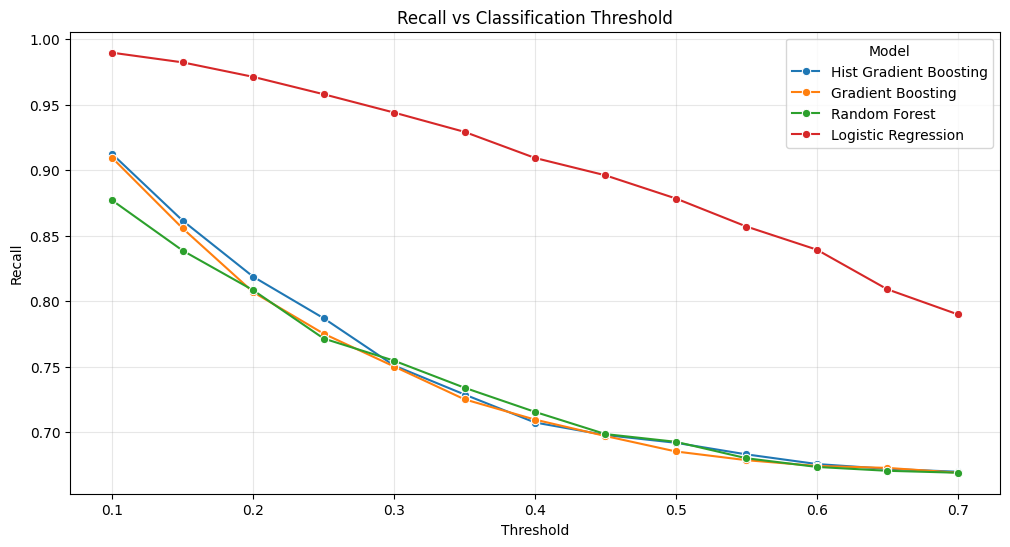

In [32]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=threshold_df,
    x='Threshold',
    y='Recall',
    hue='Model',
    marker='o'
)

plt.title('Recall vs Classification Threshold')
plt.grid(alpha=0.3)
plt.show()

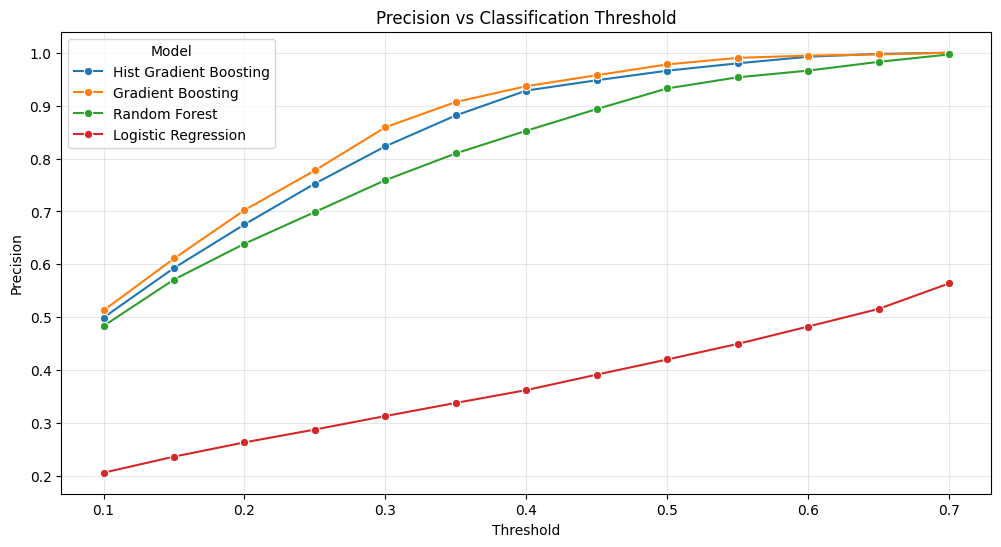

In [33]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=threshold_df,
    x='Threshold',
    y='Precision',
    hue='Model',
    marker='o'
)

plt.title('Precision vs Classification Threshold')
plt.grid(alpha=0.3)
plt.show()

Train final gradient boosting model

In [34]:
from sklearn.base import clone

final_model = clone(
    validation_models['Gradient Boosting']
)

final_model.fit(X_train, y_train)

print("Final Gradient Boosting model trained.")

Final Gradient Boosting model trained.


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

FINAL_THRESHOLD = 0.30

y_prob = final_model.predict_proba(X_test)[:, 1]

y_pred = (
    y_prob >= FINAL_THRESHOLD
).astype(int)

print("Final Model: Gradient Boosting")
print("Threshold:", FINAL_THRESHOLD)

print("\nAccuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Precision:",
      round(precision_score(y_test, y_pred), 4))

print("Recall:",
      round(recall_score(y_test, y_pred), 4))

print("F1 Score:",
      round(f1_score(y_test, y_pred), 4))

print("ROC AUC:",
      round(roc_auc_score(y_test, y_prob), 4))

print("PR AUC:",
      round(average_precision_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Final Model: Gradient Boosting
Threshold: 0.3

Accuracy: 0.9669
Precision: 0.862
Recall: 0.7441
F1 Score: 0.7987
ROC AUC: 0.9774
PR AUC: 0.8841

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98     17534
           1       0.86      0.74      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.92      0.87      0.89     19230
weighted avg       0.97      0.97      0.97     19230



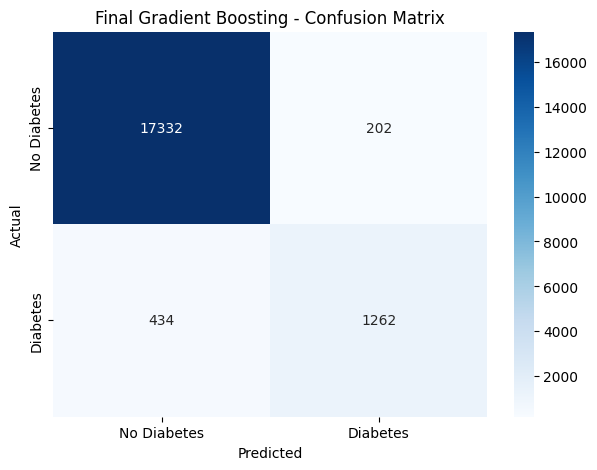

In [36]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Final Gradient Boosting - Confusion Matrix')

plt.show()